# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 5. Поиск типичных подпоследовательностей временного ряда.**

In [1]:
import os
import sys
from pathlib import Path
candidates = [Path.cwd(), Path.cwd() / 'practice' / '05 Snippets',
              Path(r'C:\Users\artem\2026-Artemov-TimeSeriesCourse\practice\05 Snippets')]
lab_dir = next(p for p in candidates if (p / 'datasets' / 'PAMAP' / 'PAMAP.txt').is_file())
os.chdir(lab_dir)
if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))
print('Рабочая папка:', Path.cwd())

Рабочая папка: C:\Users\artem\2026-Artemov-TimeSeriesCourse\practice\05 Snippets


In [2]:
%load_ext autoreload
%autoreload 2

Импорт библиотек и модулей

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numba
from scipy import signal
from stumpy import snippets
from modules.snippets import plot_snippets, plot_activity_comparison, plot_parameter_selection
from modules.analysis import (load_pamap, snippet_labels, align_to_reference,
    activity_mapping, decode_activities, majority_vote, snippet_table, parameter_sweep, ACTIVITY_NAMES)

numba.set_num_threads(min(4, numba.config.NUMBA_NUM_THREADS))
plt.style.use('default')
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'savefig.facecolor': 'white', 'savefig.transparent': False, 'font.size': 10})

### **Задача 1. Поиск сниппетов одномерного временного ряда**

В первой задаче необходимо выполнить поиск сниппетов одномерного временного ряда. Расмотрите приведенный ниже пример использования алгоритма SnipperFinder и визуализации полученных результатов для искуственного врменного ряда.

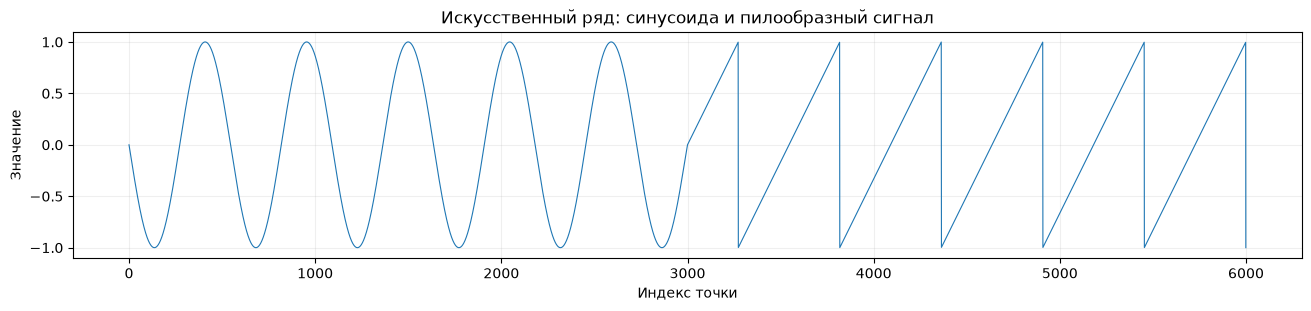

In [4]:
# Искусственный ряд: синусоида и пилообразный сигнал.
t = np.linspace(np.pi, 6 * 2 * np.pi, 3000)
ts = np.concatenate([np.sin(t), signal.sawtooth(t)])
fig, ax = plt.subplots(figsize=(13, 3), layout='constrained')
ax.plot(ts, linewidth=.8)
ax.set(title='Искусственный ряд: синусоида и пилообразный сигнал', xlabel='Индекс точки', ylabel='Значение')
ax.grid(alpha=.2)
plt.show()

In [5]:
#Поиск сниппетов
snp = snippets(ts, 600, 2, percentage=0.5)

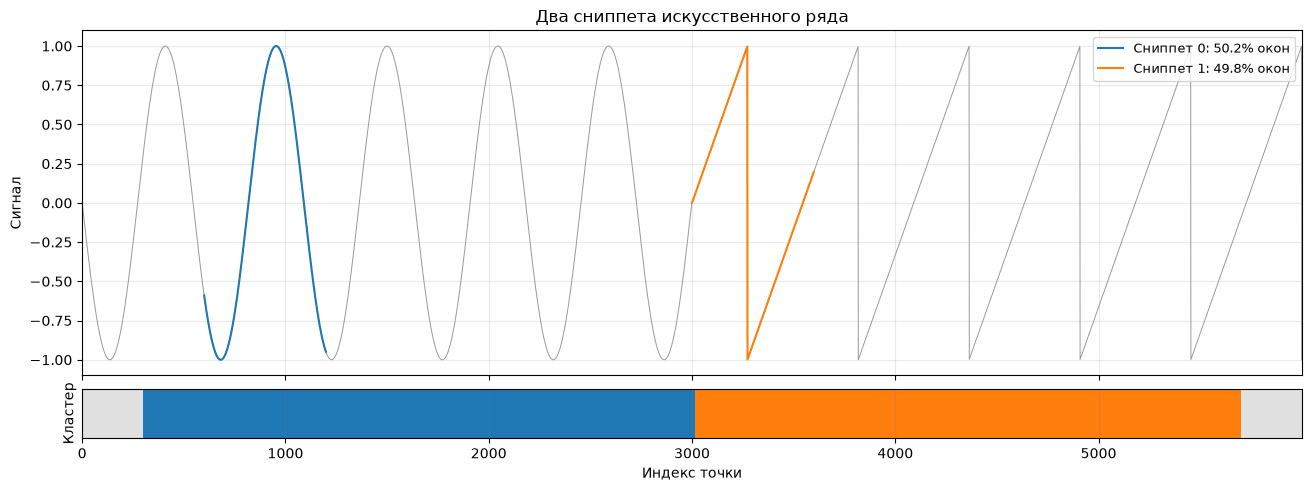

In [6]:
_ = plot_snippets(ts, snp, title='Два сниппета искусственного ряда')

Далее вам предстоит самостоятельно выполнить поиск top-$k$ типичных подпоследовательностей временного ряда (сниппетов) с помощью алгоритма SnippetFinder на наборе данных PAMAP. Описание набора данных находится в [README-файле](datasets/PAMAP/readme.md).

Выполните считывание временного ряда **показаний гироскопа на оси «Y» (угол тангажа) на временном интервале от 1790 сек. до 1930 сек.** (используя колонку с временными метками) из файла *PAMAP.txt*, который располагается в директории *./datasets/PAMAP*. Затем выполните поиск сниппетов с помощью функции `snippets()` из библиотеки stumpy. Затем визуализируйте полученные результаты, используя функцию `plot_snippets()` из модуля snippets.py.

In [7]:
pamap = load_pamap('datasets/PAMAP/PAMAP.txt', start=1790, stop=1930)
timestamps = pamap['time'].to_numpy()
gyro = {axis: pamap[f'gyro_{axis}'].to_numpy() for axis in 'XYZ'}
true_activity = pamap['activity'].to_numpy()
dt = float(np.median(np.diff(timestamps)))
assert np.allclose(np.diff(timestamps), dt)
print(f'Выбрано {len(pamap)} точек: {timestamps[0]:.2f} - {timestamps[-1]:.2f} с; частота {1/dt:.0f} Гц')
print('Время 1790 - 1795,70 с отсутствует в исходном файле; точки не добавлялись.')
print('Пропусков в выбранных трех каналах:', int(pamap.filter(like='gyro_').isna().sum().sum()))

m, k, percentage = 600, 2, 0.5
axis_results = {'Y': snippets(gyro['Y'].copy(), m, k, percentage=percentage)}
result_y = axis_results['Y']
cluster_y = snippet_labels(result_y)
centers = np.arange(len(cluster_y)) + m // 2
center_times = timestamps[centers]
truth = true_activity[centers]
print(f'Окно m={m}: {m*dt:.2f} с, внутренняя подпоследовательность s={int(np.ceil(m*percentage))} точек')
print(f'Профиль содержит {len(cluster_y)} окон; оценки относятся к их центрам.')
display(snippet_table(result_y, timestamps))

Выбрано 13430 точек: 1795.71 - 1930.00 с; частота 100 Гц
Время 1790 - 1795,70 с отсутствует в исходном файле; точки не добавлялись.
Пропусков в выбранных трех каналах: 0


Окно m=600: 6.00 с, внутренняя подпоследовательность s=300 точек
Профиль содержит 12831 окон; оценки относятся к их центрам.


,Сниппет,Начало окна,"Начало, с","Конец, с",Доля окон
0,0,6000,1855.71,1861.7,0.578443
1,1,10800,1903.71,1909.7,0.421557


Выполните визулизацию временного ряда и найденных сниппетов с помощью функции `plot_snippets()` из модуля snippets.py.

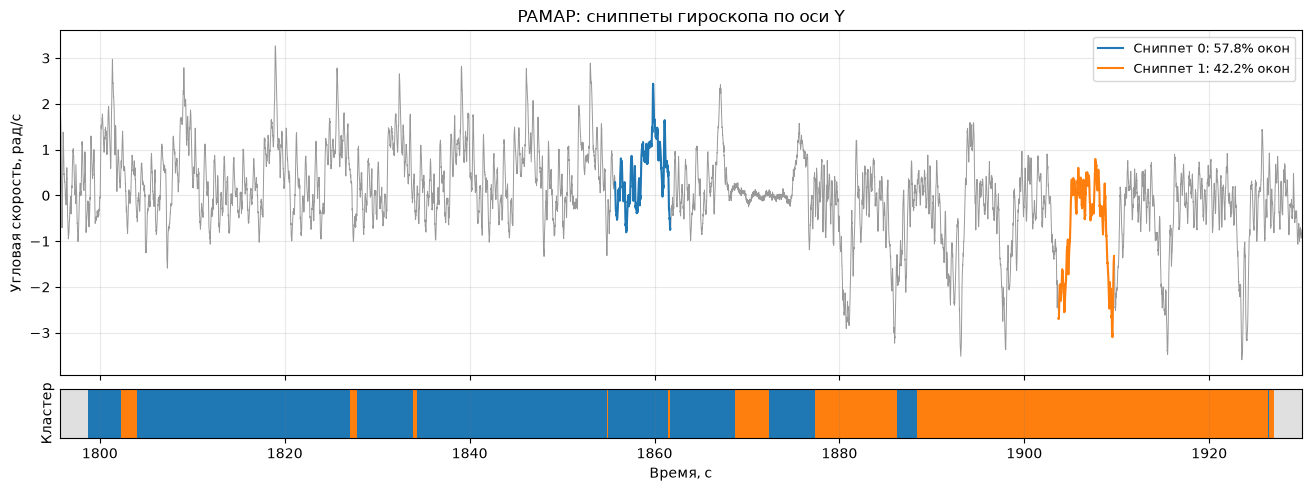

In [8]:
_ = plot_snippets(gyro['Y'], result_y, timestamps, title='PAMAP: сниппеты гироскопа по оси Y')

Оцените точность разметки, полученной при помощи сниппетов, используя исходные данные об активностях в ряде.

Кластеры и активности: {0: 'Подъем по лестнице', 1: 'Спуск по лестнице'}
Accuracy оси Y: 0.9016 (90.16%); самый частый класс: 56.39%
Оценено 12831 центров окон. Первые 300 и последние 299 точек не оцениваются.


Предсказанная активность,12,13
Истинная активность,,
12,6698,538
13,724,4871


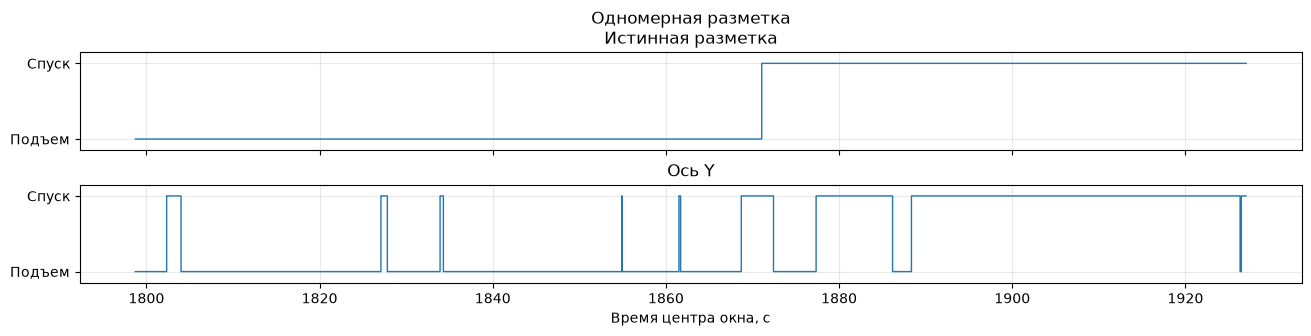

In [9]:
# Идентификаторы кластеров произвольны. Сопоставление нужно только для оценки.
cluster_to_activity = activity_mapping(cluster_y, truth, k)
predicted_y = decode_activities(cluster_y, cluster_to_activity)
accuracy_y = float(np.mean(predicted_y == truth))
baseline_accuracy = float(pd.Series(truth).value_counts(normalize=True).max())
print('Кластеры и активности:', {i: ACTIVITY_NAMES[v] for i,v in cluster_to_activity.items()})
print(f'Accuracy оси Y: {accuracy_y:.4f} ({accuracy_y:.2%}); самый частый класс: {baseline_accuracy:.2%}')
print(f'Оценено {len(truth)} центров окон. Первые {m//2} и последние {len(pamap)-1-centers[-1]} точек не оцениваются.')
display(pd.crosstab(pd.Series(truth, name='Истинная активность'),
                    pd.Series(predicted_y, name='Предсказанная активность')))
plot_activity_comparison(center_times, truth, {'Ось Y': predicted_y}, 'Одномерная разметка')

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Сниппет представляет типичное окно, а его MPdist-профиль показывает сходство с остальными окнами.
Параметры m=600, k=2 и percentage=0,5 зафиксированы по образцу; длина сниппета равна 6 секундам.
percentage задает длину внутренних подпоследовательностей для MPdist, а не долю отбрасываемых точек.
По README гироскоп измеряет угловую скорость в рад/с; это не сам угол тангажа.

На графике цветом выделены два представителя, нижняя полоса показывает выбранный для каждого
окна кластер. Серые края не получают искусственную метку: для них нет полного окна с таким центром.
Идентификаторы 12 и 13 означают подъем и спуск по лестнице и здесь остаются разными классами.
Точные доли, начала окон, accuracy и таблица ошибок приведены выше.

Для accuracy номера кластеров сопоставлены с активностями по максимальному совпадению.
Разметка не использовалась в поиске сниппетов. Это описательная оценка кластеризации
на данном отрезке, а не результат обучения и проверки на отдельных записях.

Получена accuracy оси Y 90,16% на 12831 окне; прогноз самого частого класса дал бы 56,39%.

В поставленном PAMAP.txt 20 показателей записаны строками, поэтому таблица транспонирована. После этого оси X, Y и Z выбраны из колонок 11, 12 и 13 по нумерации README; в первом задании используется колонка 12, ось Y. Фильтрация выполнена по реальным временным меткам.

### Задача 2. Разметка многомерного временного ряда

Выполните разметку многомерного временно ряда, используя **показания гироскопа по всем трем осям** из набора данных PAMAP. Используйте тот же временной интервал, что и в задаче 1. Итоговую разметку получите в результате голосования большинством.

,Сниппет,Начало окна,"Начало, с","Конец, с",Доля окон,Ось
0,0,1200,1807.71,1813.7,0.646247,X
1,1,10800,1903.71,1909.7,0.353753,X


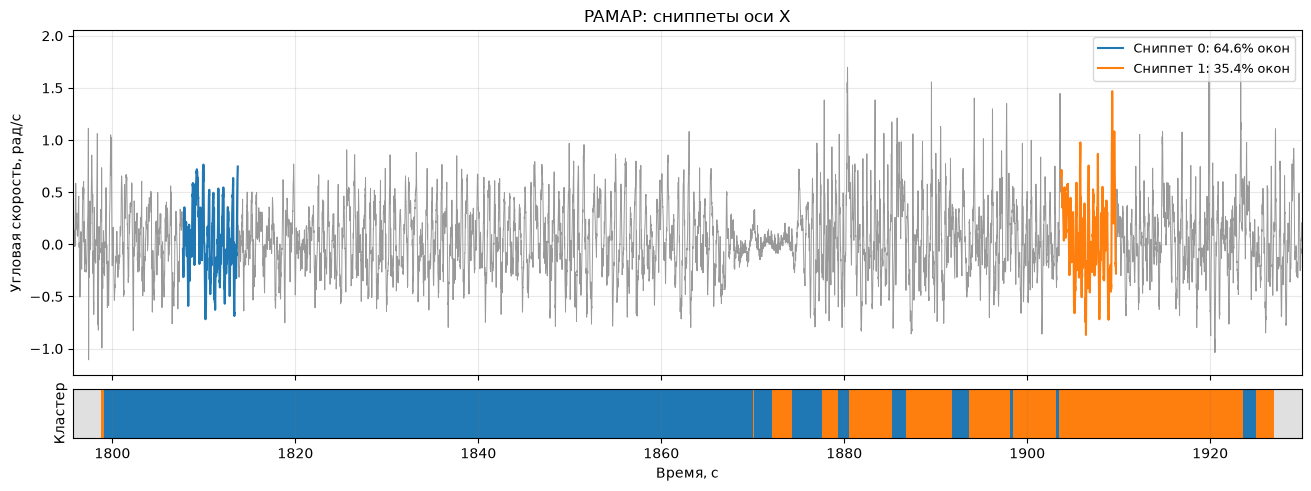

,Сниппет,Начало окна,"Начало, с","Конец, с",Доля окон,Ось
0,0,6000,1855.71,1861.7,0.641883,Z
1,1,12600,1921.71,1927.7,0.358117,Z


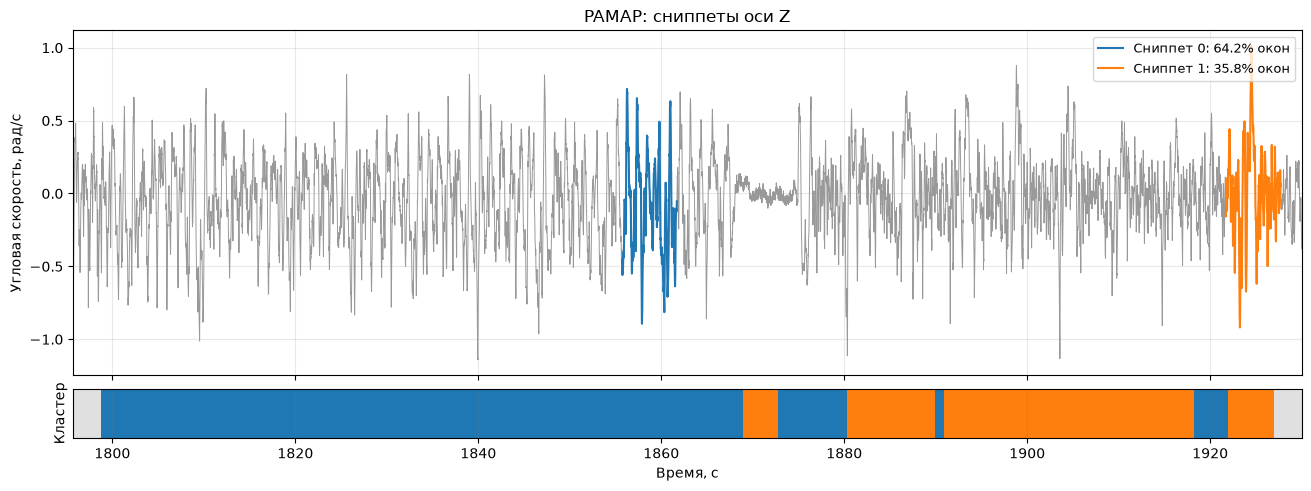

Сопоставления номеров сниппетов с опорной осью Y: {'X': {0: 0, 1: 1}, 'Y': {0: 0, 1: 1}, 'Z': {0: 0, 1: 1}}


In [10]:
for axis in ('X', 'Z'):
    axis_results[axis] = snippets(gyro[axis].copy(), m, k, percentage=percentage)
    display(snippet_table(axis_results[axis], timestamps).assign(Ось=axis))
    _ = plot_snippets(gyro[axis], axis_results[axis], timestamps, title=f'PAMAP: сниппеты оси {axis}')

raw_clusters = {axis: snippet_labels(axis_results[axis]) for axis in 'XYZ'}
aligned_clusters, permutations = {}, {}
for axis in 'XYZ':
    aligned_clusters[axis], permutations[axis] = align_to_reference(raw_clusters[axis], cluster_y, k)
print('Сопоставления номеров сниппетов с опорной осью Y:', permutations)
# Голосование выполняется после согласования номеров и без использования истинных меток.
voted_clusters = majority_vote(np.stack([aligned_clusters[axis] for axis in 'XYZ']), reference_index=1)
predicted_xyz = decode_activities(voted_clusters, cluster_to_activity)

Оцените точность разметки многомерного ряда, используя исходные данные об активностях.

,Вариант,Accuracy
0,X,0.910529
1,Y,0.901644
2,Z,0.888395
3,Голосование XYZ,0.934378


Accuracy XYZ: 0.9344 (93.44%)
Разница с Y: +3.27 процентного пункта


Предсказанная активность,12,13
Истинная активность,,
12,7020,216
13,626,4969


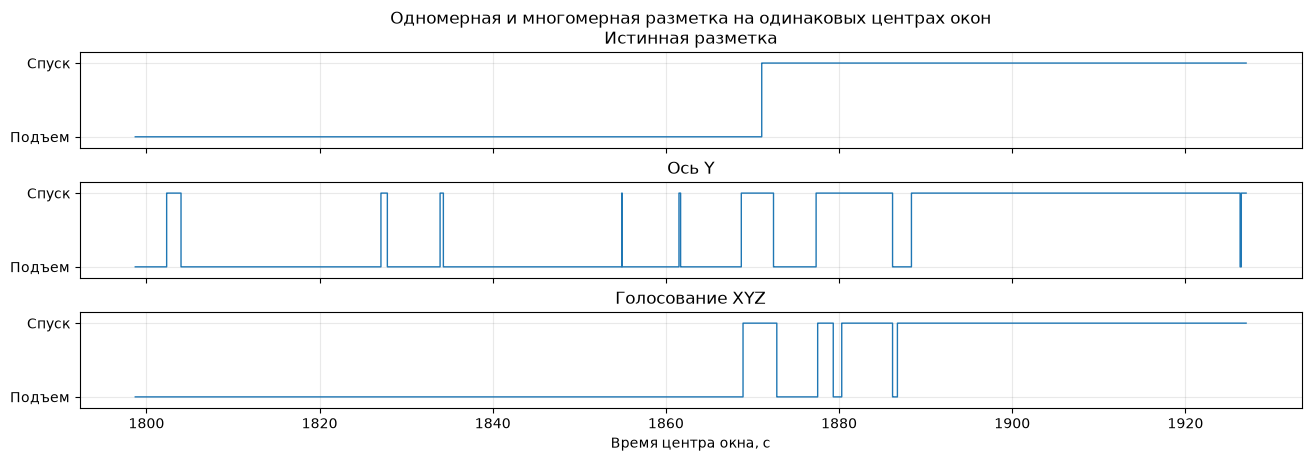

In [11]:
predictions_by_axis = {axis: decode_activities(aligned_clusters[axis], cluster_to_activity) for axis in 'XYZ'}
accuracy_xyz = float(np.mean(predicted_xyz == truth))
accuracy_table = pd.DataFrame({
    'Вариант': ['X', 'Y', 'Z', 'Голосование XYZ'],
    'Accuracy': [float(np.mean(predictions_by_axis[axis] == truth)) for axis in 'XYZ'] + [accuracy_xyz],
})
display(accuracy_table)
print(f'Accuracy XYZ: {accuracy_xyz:.4f} ({accuracy_xyz:.2%})')
print(f'Разница с Y: {(accuracy_xyz-accuracy_y)*100:+.2f} процентного пункта')
display(pd.crosstab(pd.Series(truth, name='Истинная активность'),
                    pd.Series(predicted_xyz, name='Предсказанная активность')))
plot_activity_comparison(center_times, truth, {'Ось Y': predicted_y, 'Голосование XYZ': predicted_xyz},
                         'Одномерная и многомерная разметка на одинаковых центрах окон')

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Сравните полученные разметки многомерного и одномерного рядов.

Для каждой оси выполнен отдельный поиск двух сниппетов. Их номера не обозначают виды активности
и могут переставляться между осями. Поэтому перед голосованием номера X и Z согласованы
с разметкой оси Y по пересечению предсказанных кластеров, без истинных меток.
Затем для каждого центра окна выбран класс большинства из трех осей. При двух классах
и трех голосах ничьей не возникает. Одна и та же перестановка кластеров Y в активности
используется и для одномерной оценки, и для голосования.

Таблица и график выше сравнивают X, Y, Z и голосование на одних и тех же 12831 окне.
Голосование может исправлять отдельные ошибки оси, но не обязано повышать точность:
если две оси ошибаются одновременно, большинство также ошибается.

Accuracy голосования равна 93,44%, это на 3,27 процентного пункта выше результата Y. Сопоставления кластеров и таблицы ошибок показаны выше.

## Задача 3. Подбор оптимального значения _k_


Разработайте программу, которая выполняет выполняет вычисление меры $change$ для различных значений $k$ с помощью алгоритма SnippetFinder. Проведите эксперименты, используя временной ряд из задания 2 (взяв 1 ≤ _k_ ≤ 9).

$Change_k = \frac{ProfileArea_{k-1}}{ProfileArea_k} - 1$

In [12]:
area_table, change_table, selected_k, grid_results = parameter_sweep(gyro, m=m, max_k=9, percentage=percentage)
print('ProfileArea для k=1..9:')
display(area_table)
print('Change_k = ProfileArea_(k-1) / ProfileArea_k - 1:')
display(change_table)
print(f'Предпочтительное k по максимуму change среднего профиля XYZ: {selected_k}')
print('Для k=1 change не определен: нет ProfileArea_0. Значение не заменяется нулем.')
for axis in 'XYZ':
    np.testing.assert_allclose(grid_results[axis][1][:k], axis_results[axis][1])
    np.testing.assert_allclose(grid_results[axis][4][:k], axis_results[axis][4], atol=1e-6)

ProfileArea для k=1..9:


,X,Y,Z,Среднее XYZ
k,,,,
1,182886.576672,135069.174002,165257.020367,161070.923681
2,162953.443520,108546.841988,146169.949153,139223.411553
3,147930.645156,94529.377165,136459.318372,126306.446898
4,138008.025696,87739.967878,127183.102546,117643.698707
5,128619.698576,81123.607433,118538.393200,109427.233070
6,120014.952420,75061.132703,110062.462560,101712.849228
7,111597.810040,69278.584065,101645.726391,94174.040166
8,103952.116160,63924.063860,93929.119008,87268.433009
9,96514.483618,58740.902272,86377.507237,80544.297709


Change_k = ProfileArea_(k-1) / ProfileArea_k - 1:


,X,Y,Z,Среднее XYZ
k,,,,
1,NaN,NaN,NaN,NaN
2,0.122324,0.244340,0.130581,0.156924
3,0.101553,0.148287,0.071161,0.102267
4,0.071899,0.077381,0.072936,0.073635
5,0.072993,0.081559,0.072928,0.075086
6,0.071697,0.080767,0.077010,0.075845
7,0.075424,0.083468,0.082805,0.080052
8,0.073550,0.083764,0.082154,0.079131
9,0.077062,0.088238,0.087426,0.083484


Предпочтительное k по максимуму change среднего профиля XYZ: 2
Для k=1 change не определен: нет ProfileArea_0. Значение не заменяется нулем.


Выполните визуализацию результатов экспериментов в следующем виде: отображение столбчатых диаграм со значениями $ProfileArea$ и меры $change$ в зависимости от $k$.

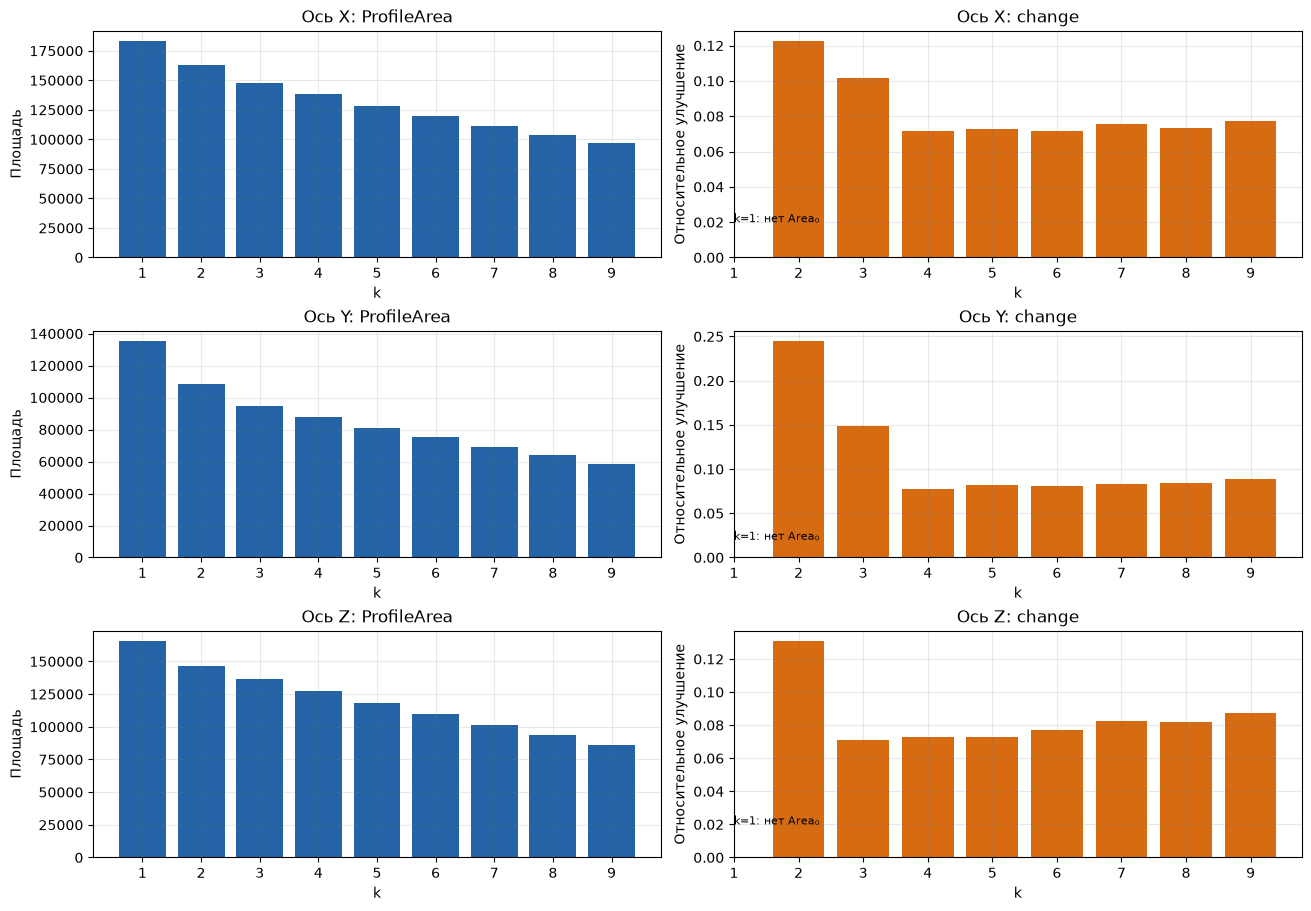

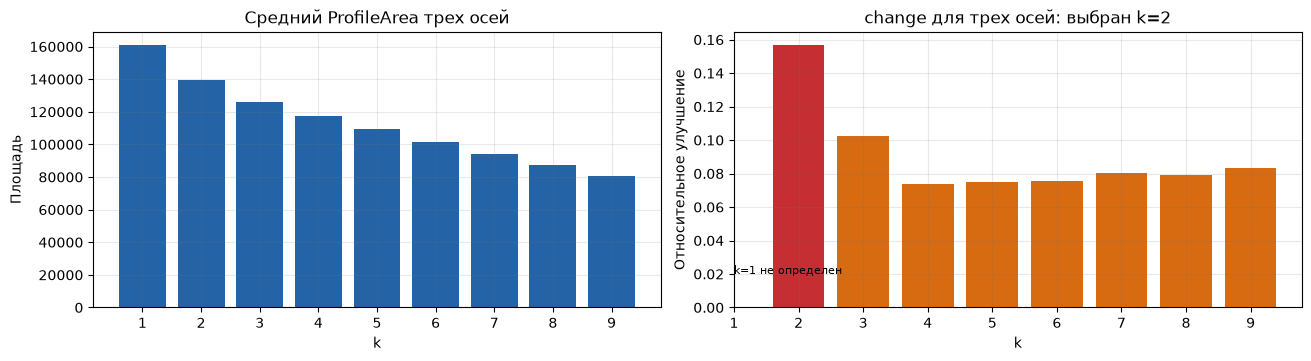

In [13]:
plot_parameter_selection(area_table, change_table, selected_k)

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Какое значение $k$ является наилучшим для используемого временного ряда?

ProfileArea_k вычислена как сумма поточечных минимумов MPdist-профилей первых k сниппетов.
Это площадь общего нижнего профиля, а не сумма площадей отдельных представителей.
При добавлении сниппета она не возрастает. В STUMPY жадный порядок выбора не зависит
от запрошенного максимального k, поэтому один поиск девяти сниппетов на каждой оси
дает точные результаты для всех префиксов k=1..9. Совпадение первых двух с задачами 1 и 2 проверено.

Для многомерного ряда площади X, Y и Z усреднены при одинаковых m и percentage.
Сначала вычислен средний ProfileArea, затем из него вычислен change. Это явно заданный
способ объединения трех одномерных поисков. Отдельные оси также показаны на диаграммах.
У k=1 нет предыдущего ProfileArea_0, поэтому первый change отсутствует.

Красный столбец итоговой диаграммы показывает выбранный максимум change. Такой k
дает наибольшее относительное снижение площади среди проверенных значений.
Выбор сделан без accuracy и без истинной разметки. Это предпочтительное число
представителей по данному критерию при m=600, а не доказательство единственного
оптимума для любой длины окна или новых данных. Для данного ряда выбрано k=2, change=0,1569.